# PINNs for Mechanical Engineers — Tutorial 7: NACA 0012 Airfoil
### A published laminar benchmark: geometry, pressure, wake, and aerodynamic drag

*📺 Video on YouTube | 🐍 Python · PyTorch | Advanced*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

This series applies physics-informed neural networks to mechanical-engineering problems. Tutorial 6 introduced separation and reattachment in a backward-facing step. Tutorial 7 keeps the same steady incompressible equations, but replaces the polygonal channel with a **curved external-flow geometry**: a NACA 0012 airfoil.

| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ Published |
| 2 | 2D Steady Heat Conduction | mixed Dirichlet/Neumann BCs | ✅ Published |
| 3 | Linear Elasticity — plate with a hole | vector fields, stress concentration | ✅ Published |
| 4 | Inverse Heat Transfer | parameter identification | ✅ Published |
| 5 | Euler–Bernoulli Beam | fourth-order PDE | ✅ Published |
| 6 | Backward-Facing Step | separation and reattachment | ✅ Published |
| **7** | **NACA 0012 Airfoil** | **curved boundary, pressure coefficient, drag** | **← You are here** |
| 8 | Unsteady Airfoil Wake | vortex shedding and force history | Next |

The objective is not to make an industrial aerodynamic solver. It is to build a transparent PINN benchmark that can be checked one physical quantity at a time.


## 1 — What You Will Learn

By the end of this notebook you will have:

- Generated the **NACA 0012** surface directly from its four-digit thickness equation
- Solved the **steady incompressible 2D Navier–Stokes equations** outside the airfoil
- Sampled a rectangular far field while removing points inside a curved solid body
- Added extra collocation points near the airfoil and in its wake
- Applied uniform far-field flow, no slip on the airfoil, and an outflow condition
- Trained a velocity–pressure network that predicts $(u,v,p)$
- Plotted velocity, pressure, streamlines, and surface pressure coefficient $C_p$
- Integrated pressure and viscous traction to estimate $C_D$ and $C_L$
- Compared the predicted drag with a **published NACA 0012 benchmark range**
- Checked independent residuals, wall slip, flow symmetry, and mass conservation

**Scope:** steady, two-dimensional, incompressible, laminar flow at $Re_c=500$ and zero angle of attack. No turbulence model is used.


## 2 — The problem and its published reference

We solve the non-dimensional steady incompressible Navier–Stokes equations:

$$
\begin{aligned}
u u_x+v u_y &= -p_x+\frac{1}{Re_c}(u_{xx}+u_{yy}),\\
u v_x+v v_y &= -p_y+\frac{1}{Re_c}(v_{xx}+v_{yy}),\\
u_x+v_y &= 0.
\end{aligned}
$$

The chord $c$ is the reference length, the free-stream velocity $U_\infty$ is the reference velocity, and pressure is scaled by $\rho U_\infty^2$:

$$Re_c=\frac{U_\infty c}{\nu}.$$


### NACA 0012 geometry

For a symmetric NACA four-digit airfoil with thickness ratio $t=0.12$,

$$
y_t(x)=5t\left(0.2969\sqrt{x}-0.1260x-0.3516x^2+0.2843x^3-0.1015x^4\right),
\qquad 0\le x\le1.
$$

The upper and lower surfaces are $y=\pm y_t(x)$. The standard $-0.1015$ coefficient leaves a very small finite trailing-edge thickness, which we close with a short vertical segment.

### Published benchmark used here

Xiao *et al.* (Ocean Engineering 319, 2025, 120239) use steady incompressible NACA 0012 flow as an IBM-PINN benchmark. For $Re_c=500$ and $\alpha=0^\circ$, their comparison table reports:

| Reference solution | Published $C_D$ |
|---|---:|
| CFL3D | 0.1762 |
| Imamura *et al.* | 0.1736 |
| Immersed-boundary reference | 0.1759 |
| Data-assisted IBM-PINN (PLF) | 0.1748 |

We therefore use **$0.1736\le C_D\le0.1762$** as a practical comparison band. Small differences in far-field size, trailing-edge convention, sampling, and force integration can shift the last digits.

**Primary benchmark citation:** Y. Xiao, L. M. Yang, C. Shu, X. Shen, Y. J. Du, Y. X. Song, *Immersed boundary method-incorporated physics-informed neural network for simulation of incompressible flows around immersed objects*, Ocean Engineering 319 (2025) 120239. DOI: `10.1016/j.oceaneng.2024.120239`.


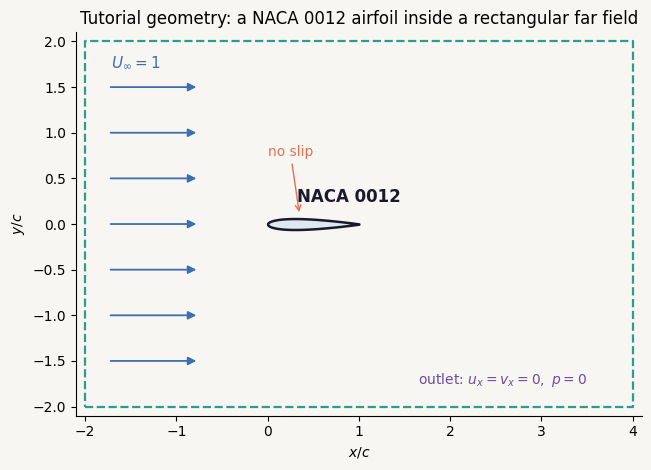

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Polygon

BG="#f7f6f2"; CORAL="#E76F51"; TEAL="#2A9D8F"; INK="#1A1A2E"; PUR="#6D4C9E"; BLUE="#3B6FB0"

def naca0012_thickness_np(x, thickness=0.12):
    x=np.asarray(x)
    return 5*thickness*(0.2969*np.sqrt(np.clip(x,0,None))-0.1260*x-0.3516*x**2+0.2843*x**3-0.1015*x**4)

# cosine spacing places more points at the leading and trailing edges
beta=np.linspace(0,np.pi,300)
x_surface=0.5*(1-np.cos(beta))
y_surface=naca0012_thickness_np(x_surface)

fig,ax=plt.subplots(figsize=(12,4.8)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
ax.fill_between(x_surface,-y_surface,y_surface,color="#dfe8ef",edgecolor=INK,lw=1.8,zorder=4)

# far-field box used by the PINN
ax.plot([-2,4,4,-2,-2],[-2,-2,2,2,-2],color=TEAL,lw=1.6,ls='--')

# free-stream arrows
for y0 in np.linspace(-1.5,1.5,7):
    ax.add_patch(FancyArrowPatch((-1.75,y0),(-0.75,y0),arrowstyle='-|>',mutation_scale=12,
                                 color=BLUE,lw=1.3))
ax.text(-1.72,1.72,r'$U_\infty=1$',color=BLUE,fontsize=11)
ax.text(0.32,0.24,'NACA 0012',color=INK,fontsize=12,weight='bold')
ax.text(1.65,-1.75,r'outlet: $u_x=v_x=0,\ p=0$',color=PUR,fontsize=10)
ax.annotate('no slip',xy=(0.35,0.10),xytext=(0.0,0.75),
            arrowprops=dict(arrowstyle='->',color=CORAL),color=CORAL,fontsize=10)

ax.set_xlim(-2.1,4.1); ax.set_ylim(-2.1,2.1); ax.set_aspect('equal')
ax.set_xlabel('$x/c$'); ax.set_ylabel('$y/c$')
ax.set_title('Tutorial geometry: a NACA 0012 airfoil inside a rectangular far field')
for q in ['top','right']: ax.spines[q].set_visible(False)
plt.tight_layout(); plt.show()


### Boundary conditions

| Boundary | Location | Condition |
|----------|----------|-----------|
| Left far field | $x=-2$ | $u=1$, $v=0$ |
| Top and bottom far field | $y=\pm2$ | $u=1$, $v=0$ |
| Outlet | $x=4$ | $u_x=0$, $v_x=0$, $p=0$ |
| Airfoil | NACA 0012 surface | $u=0$, $v=0$ |

The outlet pressure fixes the arbitrary pressure gauge. We do **not** prescribe the pressure distribution on the airfoil; the network must obtain it from momentum conservation and no slip.

### What counts as validation?

There is no analytical viscous field for this case. We therefore validate in layers:

1. independent momentum and continuity residuals are small;
2. far-field and no-slip conditions are satisfied;
3. upper and lower fields remain symmetric at $\alpha=0^\circ$;
4. mass flow is approximately conserved;
5. $C_L$ is close to zero;
6. $C_D$ approaches the published $0.1736$–$0.1762$ band.

The short CPU mode only checks that every cell runs. Benchmark-quality force coefficients require the full GPU training mode.


---

## 3 — Imports and Setup

The main settings remain in one visible cell, as in Tutorial 6. CUDA automatically selects the full run; CPU selects a short code check. Start with the defaults before changing network size, sample count, or loss weights.


In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math, time

# reproducibility
torch.manual_seed(0)
np.random.seed(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# geometry and flow
XMIN=-2.0; XMAX=4.0; YMIN=-2.0; YMAX=2.0
CHORD=1.0; THICKNESS=0.12
RE_TARGET=500.0

# automatic full GPU run; set FULL_TRAINING=False for a quick code check
FULL_TRAINING = device.type == 'cuda'
N_f = 12000 if FULL_TRAINING else 600              # interior collocation points
N_b = 500 if FULL_TRAINING else 50                 # each outer boundary
N_airfoil = 1400 if FULL_TRAINING else 140         # curved no-slip boundary
ADAM_ITERS_PER_STAGE = 2500 if FULL_TRAINING else 5
LBFGS_ITERS = 400 if FULL_TRAINING else 3
LOG_EVERY = 100 if FULL_TRAINING else 1
RUN_LBFGS = True

# introduce inertia gradually while remaining laminar
RE_STAGES=[50.0,200.0,RE_TARGET]

print(f"Problem: steady 2D laminar NACA 0012 | alpha=0 deg | target Re_c={RE_TARGET:g}")
print(f"Training: N_f={N_f}, N_b={N_b}, N_airfoil={N_airfoil}")
print(f"Adam/stage={ADAM_ITERS_PER_STAGE}, L-BFGS={LBFGS_ITERS}")


Using device: cuda
GPU: Tesla T4
Problem: steady 2D laminar NACA 0012 | alpha=0 deg | target Re_c=500
Training: N_f=12000, N_b=500, N_airfoil=1400
Adam/stage=2500, L-BFGS=400


---

## 4 — The reference quantities

Before training, code and check everything that is known exactly:

- the NACA 0012 thickness function;
- the airfoil mask;
- the uniform free stream;
- the symmetry result $C_L=0$ for the ideal zero-incidence configuration;
- the published drag comparison band.

These checks catch geometry mistakes before they become training problems.


In [3]:
def naca_thickness(x):
    "NACA 0012 half-thickness for 0 <= x <= 1."
    x=torch.clamp(x,min=0.0)
    return 5.0*THICKNESS*(0.2969*torch.sqrt(x+1e-12)-0.1260*x-0.3516*x**2
                          +0.2843*x**3-0.1015*x**4)

def naca_thickness_numpy(x):
    x=np.asarray(x)
    return 5.0*THICKNESS*(0.2969*np.sqrt(np.clip(x,0,None))-0.1260*x-0.3516*x**2
                          +0.2843*x**3-0.1015*x**4)

def inside_airfoil_numpy(x,y):
    x=np.asarray(x); y=np.asarray(y)
    return (x>=0.0)&(x<=CHORD)&(np.abs(y)<=naca_thickness_numpy(x))

# exact geometry checks
x_check=np.linspace(0,1,2001)
yt_check=naca_thickness_numpy(x_check)
i_max=np.argmax(yt_check)
print(f"maximum full thickness: {2*yt_check[i_max]:.5f} c at x/c={x_check[i_max]:.4f}")
print(f"leading-edge thickness: {2*yt_check[0]:.6f} c")
print(f"trailing-edge thickness: {2*yt_check[-1]:.6f} c")

CD_REFERENCE_LOW=0.1736
CD_REFERENCE_HIGH=0.1762
CD_REFERENCE_MID=0.5*(CD_REFERENCE_LOW+CD_REFERENCE_HIGH)
CL_REFERENCE=0.0
print(f"published drag band: {CD_REFERENCE_LOW:.4f} <= C_D <= {CD_REFERENCE_HIGH:.4f}")
print(f"symmetry reference: C_L = {CL_REFERENCE:.1f}")


maximum full thickness: 0.12003 c at x/c=0.3000
leading-edge thickness: 0.000000 c
trailing-edge thickness: 0.002520 c
published drag band: 0.1736 <= C_D <= 0.1762
symmetry reference: C_L = 0.0


---

## 5 — Collocation and boundary points

We create four clearly separated point families:

1. **Interior points:** enforce the three Navier–Stokes residuals.
2. **Far-field points:** enforce $u=1$ and $v=0$ on the left, top, and bottom boundaries.
3. **Outlet points:** enforce $u_x=v_x=0$ and $p=0$.
4. **Airfoil points:** enforce no slip on the upper surface, lower surface, and tiny trailing-edge face.

Interior sampling is split into three parts:

- a global box for the overall flow;
- a small box around the airfoil for boundary-layer resolution;
- a downstream strip for wake resolution.

Every proposed interior point is rejected if it lies inside the solid airfoil.


In [4]:
rng=np.random.default_rng(42)

def sample_box_outside(n,x0,x1,y0,y1):
    "Rejection sample n points from a box, excluding the airfoil interior."
    pieces=[]; count=0
    while count<n:
        m=max(2*(n-count),200)
        x=rng.uniform(x0,x1,m); y=rng.uniform(y0,y1,m)
        keep=~inside_airfoil_numpy(x,y)
        q=np.column_stack([x[keep],y[keep]])
        pieces.append(q); count+=len(q)
    return torch.tensor(np.vstack(pieces)[:n],dtype=torch.float32,device=device)

def sample_interior(n):
    n_global=int(0.50*n)
    n_near=int(0.35*n)
    n_wake=n-n_global-n_near
    global_pts=sample_box_outside(n_global,XMIN,XMAX,YMIN,YMAX)
    near_pts=sample_box_outside(n_near,-0.20,1.25,-0.35,0.35)
    wake_pts=sample_box_outside(n_wake,0.85,3.25,-0.60,0.60)
    return torch.cat([global_pts,near_pts,wake_pts],dim=0)

def airfoil_boundary_points(n_total):
    "Cosine-spaced upper/lower surfaces plus the finite trailing-edge face."
    n_side=max(20,(n_total-10)//2)
    beta=torch.linspace(0,math.pi,n_side,device=device).reshape(-1,1)
    x=0.5*(1-torch.cos(beta))
    yt=naca_thickness(x)
    upper=torch.cat([x,yt],dim=1)
    lower=torch.cat([x,-yt],dim=1)
    n_te=max(6,n_total-2*n_side)
    y_te=torch.linspace(-naca_thickness(torch.ones(1,device=device)).item(),
                         naca_thickness(torch.ones(1,device=device)).item(),n_te,device=device).reshape(-1,1)
    te=torch.cat([torch.ones_like(y_te),y_te],dim=1)
    return torch.cat([upper,lower,te],dim=0)

# interior physics points
xy_f=sample_interior(N_f).requires_grad_(True)

# far-field velocity boundaries
left=torch.cat([XMIN*torch.ones(N_b,1,device=device),
                torch.linspace(YMIN,YMAX,N_b,device=device).reshape(-1,1)],dim=1)
top=torch.cat([torch.linspace(XMIN,XMAX,N_b,device=device).reshape(-1,1),
               YMAX*torch.ones(N_b,1,device=device)],dim=1)
bottom=torch.cat([torch.linspace(XMIN,XMAX,N_b,device=device).reshape(-1,1),
                  YMIN*torch.ones(N_b,1,device=device)],dim=1)
xy_far=torch.cat([left,top,bottom],dim=0)

# pressure/outflow boundary
xy_out=torch.cat([XMAX*torch.ones(N_b,1,device=device),
                  torch.linspace(YMIN,YMAX,N_b,device=device).reshape(-1,1)],dim=1).requires_grad_(True)

# curved no-slip boundary
xy_airfoil=airfoil_boundary_points(N_airfoil)

print(f"interior collocation points: {xy_f.shape[0]}")
print(f"far-field points: {xy_far.shape[0]} ({N_b} on each of three segments)")
print(f"outlet points: {xy_out.shape[0]}")
print(f"airfoil points: {xy_airfoil.shape[0]}")


interior collocation points: 12000
far-field points: 1500 (500 on each of three segments)
outlet points: 500
airfoil points: 1400


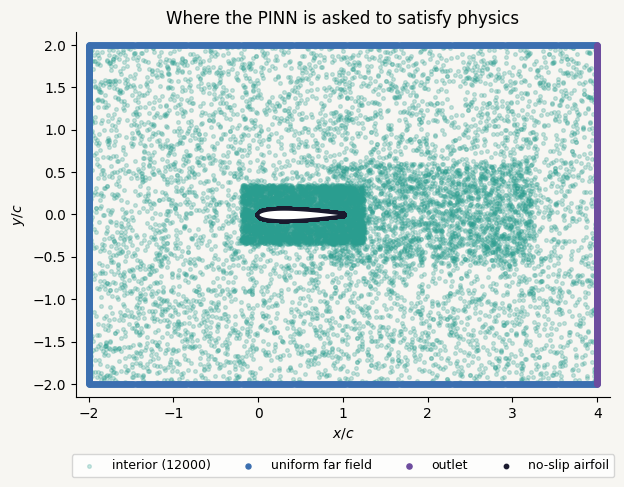

In [5]:
def np2(t):
    return t.detach().cpu().numpy()

CORAL="#E76F51"; TEAL="#2A9D8F"; INK="#1A1A2E"; PUR="#6D4C9E"; BLUE="#3B6FB0"; BG="#f7f6f2"
fig,ax=plt.subplots(figsize=(12,5.0)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)

f=np2(xy_f); bf=np2(xy_far); bo=np2(xy_out); ba=np2(xy_airfoil)
ax.scatter(f[:,0],f[:,1],s=7,alpha=0.24,color=TEAL,label=f"interior ({len(f)})")
ax.scatter(bf[:,0],bf[:,1],s=13,color=BLUE,label="uniform far field")
ax.scatter(bo[:,0],bo[:,1],s=14,color=PUR,label="outlet")
ax.scatter(ba[:,0],ba[:,1],s=10,color=INK,label="no-slip airfoil")

xpoly=np.linspace(0,1,500); ypoly=naca_thickness_numpy(xpoly)
ax.fill_between(xpoly,-ypoly,ypoly,color='white',edgecolor=INK,lw=1.2,zorder=5)
ax.set_xlim(XMIN-0.15,XMAX+0.15); ax.set_ylim(YMIN-0.15,YMAX+0.15); ax.set_aspect('equal')
ax.set_xlabel('$x/c$'); ax.set_ylabel('$y/c$')
ax.set_title('Where the PINN is asked to satisfy physics')
ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.14),ncol=4,fontsize=9)
for q in ['top','right']: ax.spines[q].set_visible(False)
plt.tight_layout(); plt.show()


---

## 6 — The network

The architecture deliberately matches Tutorial 6:

- input: $(x,y)$;
- output: $(u,v,p)$;
- five hidden `tanh` layers;
- Xavier initialization;
- linear input scaling to $[-1,1]^2$.

Input scaling is important because the domain extends from $x=-2$ to $x=4$, while the airfoil thickness is only about $0.12c$.


In [6]:
class PINN(nn.Module):
    "Input (x,y) -> outputs (u,v,p)."
    def __init__(self,n_hidden=80,n_layers=5):
        super().__init__()
        layers=[nn.Linear(2,n_hidden),nn.Tanh()]
        for _ in range(n_layers-1):
            layers += [nn.Linear(n_hidden,n_hidden),nn.Tanh()]
        layers += [nn.Linear(n_hidden,3)]
        self.net=nn.Sequential(*layers)
        self.register_buffer('lb',torch.tensor([XMIN,YMIN]))
        self.register_buffer('ub',torch.tensor([XMAX,YMAX]))
        for m in self.net:
            if isinstance(m,nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self,xy):
        z=2.0*(xy-self.lb)/(self.ub-self.lb)-1.0
        return self.net(z)

model=PINN().to(device)
n_params=sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params}")


PINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=80, bias=True)
    (1): Tanh()
    (2): Linear(in_features=80, out_features=80, bias=True)
    (3): Tanh()
    (4): Linear(in_features=80, out_features=80, bias=True)
    (5): Tanh()
    (6): Linear(in_features=80, out_features=80, bias=True)
    (7): Tanh()
    (8): Linear(in_features=80, out_features=80, bias=True)
    (9): Tanh()
    (10): Linear(in_features=80, out_features=3, bias=True)
  )
)
Trainable parameters: 26403


---

## 7 — The predicted fields and automatic differentiation

This section introduces only two helper functions:

1. `fields(xy)` splits the three network outputs into $u$, $v$, and $p$.
2. `grad(output, input)` asks PyTorch for first derivatives while retaining the graph for second derivatives.

We check tensor shapes immediately. A shape error is much easier to fix here than inside the training loop.


In [7]:
def fields(xy):
    "Network fields u(x,y), v(x,y), p(x,y)."
    out=model(xy)
    return out[:,0:1],out[:,1:2],out[:,2:3]

def grad(o,i):
    return torch.autograd.grad(o,i,torch.ones_like(o),create_graph=True,retain_graph=True)[0]

# verify shapes before training
u0,v0,p0=fields(xy_f[:8])
print(f"u shape: {tuple(u0.shape)} | v shape: {tuple(v0.shape)} | p shape: {tuple(p0.shape)}")
print(f"untrained mean values: u={u0.mean().item():+.3e}, v={v0.mean().item():+.3e}, p={p0.mean().item():+.3e}")


u shape: (8, 1) | v shape: (8, 1) | p shape: (8, 1)
untrained mean values: u=-3.562e-02, v=-2.681e-02, p=+3.330e-02


---

## 8 — The residual: momentum plus continuity

For each interior point, the network must satisfy three equations:

$$
\begin{aligned}
r_x &= u u_x+v u_y+p_x-\frac{u_{xx}+u_{yy}}{Re_c},\\
r_y &= u v_x+v v_y+p_y-\frac{v_{xx}+v_{yy}}{Re_c},\\
r_c &= u_x+v_y.
\end{aligned}
$$

The first derivatives give convection, pressure gradient, and continuity. A second automatic-differentiation call gives viscous diffusion.


In [8]:
def residuals(xy,Re):
    "x-momentum, y-momentum, and continuity residuals."
    u,v,p=fields(xy)

    gu=grad(u,xy); gv=grad(v,xy); gp=grad(p,xy)
    u_x,u_y=gu[:,0:1],gu[:,1:2]
    v_x,v_y=gv[:,0:1],gv[:,1:2]
    p_x,p_y=gp[:,0:1],gp[:,1:2]

    u_xx=grad(u_x,xy)[:,0:1]; u_yy=grad(u_y,xy)[:,1:2]
    v_xx=grad(v_x,xy)[:,0:1]; v_yy=grad(v_y,xy)[:,1:2]

    r_x=u*u_x+v*u_y+p_x-(u_xx+u_yy)/Re
    r_y=u*v_x+v*v_y+p_y-(v_xx+v_yy)/Re
    r_c=u_x+v_y
    return r_x,r_y,r_c

# demo on the untrained network
r_x,r_y,r_c=residuals(xy_f[:64],RE_TARGET)
print(f"residual shapes: {tuple(r_x.shape)}, {tuple(r_y.shape)}, {tuple(r_c.shape)}")
print(f"untrained RMS: rx={r_x.square().mean().sqrt().item():.3e}, "
      f"ry={r_y.square().mean().sqrt().item():.3e}, rc={r_c.square().mean().sqrt().item():.3e}")


residual shapes: (64, 1), (64, 1), (64, 1)
untrained RMS: rx=4.327e-02, ry=4.392e-02, rc=4.747e-02


---

## 9 — The loss

The total loss is kept visible rather than hidden in a training class:

$$
\mathcal L=\mathcal L_{PDE}
+w_f\mathcal L_{far}
+w_a\mathcal L_{airfoil}
+w_o\mathcal L_{outlet}.
$$

| Component | What it enforces |
|---|---|
| `loss_pde` | momentum and continuity in the fluid |
| `loss_far` | $u=1$, $v=0$ on left, top, and bottom |
| `loss_airfoil` | $u=v=0$ on the NACA surface |
| `loss_outlet` | $u_x=v_x=0$, $p=0$ at the outlet |

The airfoil receives the largest boundary weight because small wall-slip errors can strongly contaminate force integration.


In [9]:
W_FAR=8.0
W_AIRFOIL=20.0
W_OUTLET=1.0

def mse(z): return (z**2).mean()

def compute_losses(Re):
    # interior Navier-Stokes equations
    r_x,r_y,r_c=residuals(xy_f,Re)
    loss_pde=mse(r_x)+mse(r_y)+mse(r_c)

    # uniform free stream
    u_f,v_f,_=fields(xy_far)
    loss_far=mse(u_f-1.0)+mse(v_f)

    # no-slip airfoil
    u_a,v_a,_=fields(xy_airfoil)
    loss_airfoil=mse(u_a)+mse(v_a)

    # outlet: zero velocity gradients and pressure gauge
    u_o,v_o,p_o=fields(xy_out)
    u_x=grad(u_o,xy_out)[:,0:1]
    v_x=grad(v_o,xy_out)[:,0:1]
    loss_outlet=mse(u_x)+mse(v_x)+mse(p_o)
    return loss_pde,loss_far,loss_airfoil,loss_outlet

def total_loss(Re):
    lp,lf,la,lo=compute_losses(Re)
    return lp+W_FAR*lf+W_AIRFOIL*la+W_OUTLET*lo

# demo on the untrained network
lp,lf,la,lo=compute_losses(RE_STAGES[0])
print(f"untrained: pde={lp.item():.3e} far={lf.item():.3e} airfoil={la.item():.3e} outlet={lo.item():.3e}")


untrained: pde=6.511e-03 far=9.636e-01 airfoil=3.931e-04 outlet=2.012e-02


---

## 10 — Two-phase training: Adam → L-BFGS

Training follows the same pattern as Tutorial 6.

### Phase A — Adam with Reynolds-number continuation

The network first solves a more viscous problem and then moves through

$$Re_c=50\rightarrow200\rightarrow500.$$

This does not add turbulence. It simply gives the optimizer a smoother starting problem.

### Phase B — L-BFGS at the target Reynolds number

L-BFGS uses the Adam result as its starting point and refines the same total loss. During training we record:

- every loss component;
- the minimum streamwise velocity in the wake;
- mass-flow error near the outlet.


In [10]:
@torch.no_grad()
def mass_flow(x0,n=301):
    y=torch.linspace(YMIN,YMAX,n,device=device).reshape(-1,1)
    x=x0*torch.ones_like(y)
    u,_,_=fields(torch.cat([x,y],dim=1))
    return torch.trapz(u[:,0],y[:,0]).item()

@torch.no_grad()
def minimum_wake_velocity():
    x=torch.linspace(1.05,3.0,90,device=device)
    y=torch.linspace(-0.45,0.45,45,device=device)
    X,Y=torch.meshgrid(x,y,indexing='ij')
    u,_,_=fields(torch.stack([X.flatten(),Y.flatten()],dim=1))
    return u.min().item()

history={"epoch":[],"total":[],"pde":[],"far":[],"airfoil":[],"outlet":[],
         "wake":[],"mass":[],"phase":[],"Re":[]}

def record(epoch,phase,Re):
    lp,lf,la,lo=compute_losses(Re)
    history["epoch"].append(epoch)
    history["total"].append((lp+W_FAR*lf+W_AIRFOIL*la+W_OUTLET*lo).item())
    history["pde"].append(lp.item()); history["far"].append(lf.item())
    history["airfoil"].append(la.item()); history["outlet"].append(lo.item())
    history["wake"].append(minimum_wake_velocity())
    history["mass"].append(abs(mass_flow(3.5)-(YMAX-YMIN)))
    history["phase"].append(phase); history["Re"].append(Re)

# --- Stage 1: Adam, with laminar Re continuation ---
opt=torch.optim.Adam(model.parameters(),lr=1e-3)
step=0; start=time.time()
for Re in RE_STAGES:
    print(f"\nAdam stage: Re_c={Re:g}")
    for local in range(ADAM_ITERS_PER_STAGE+1):
        opt.zero_grad(); total_loss(Re).backward(); opt.step()
        if local%LOG_EVERY==0:
            record(step,"Adam",Re)
            print(f"[Adam] step={step:5d} Re={Re:5.1f} loss={history['total'][-1]:.3e} "
                  f"wake_min={history['wake'][-1]:+.3e} mass_err={history['mass'][-1]:.2e}")
        step+=1

# --- Stage 2: L-BFGS at the target Reynolds number ---
HANDOFF=step
if RUN_LBFGS:
    opt=torch.optim.LBFGS(model.parameters(),lr=1.0,max_iter=LBFGS_ITERS,history_size=50,
                          line_search_fn='strong_wolfe',tolerance_grad=1e-10,tolerance_change=1e-12)
    calls=[0]
    def closure():
        opt.zero_grad(); L=total_loss(RE_TARGET); L.backward(); calls[0]+=1
        if calls[0]%max(1,LBFGS_ITERS//10)==0:
            record(HANDOFF+calls[0],"LBFGS",RE_TARGET)
        return L
    opt.step(closure)

record(HANDOFF+LBFGS_ITERS+1,"LBFGS",RE_TARGET)
print(f"\nTraining complete in {(time.time()-start)/60:.2f} min")
print(f"final minimum wake u = {minimum_wake_velocity():+.4f}")
print(f"final outlet mass-flow error = {abs(mass_flow(3.5)-(YMAX-YMIN)):.3e}")

torch.save({"model_state":model.state_dict(),"history":history,"Re":RE_TARGET},
           "naca0012_pinn_tutorial7.pt")
print("saved: naca0012_pinn_tutorial7.pt")



Adam stage: Re_c=50
[Adam] step=    0 Re= 50.0 loss=6.337e+00 wake_min=-2.892e-01 mass_err=5.41e+00
[Adam] step=  100 Re= 50.0 loss=1.585e-01 wake_min=-4.355e-01 mass_err=2.28e+00
[Adam] step=  200 Re= 50.0 loss=2.535e-02 wake_min=+9.080e-04 mass_err=1.51e+00
[Adam] step=  300 Re= 50.0 loss=1.718e-02 wake_min=+1.086e-02 mass_err=1.47e+00
[Adam] step=  400 Re= 50.0 loss=1.459e-02 wake_min=+9.920e-03 mass_err=1.40e+00
[Adam] step=  500 Re= 50.0 loss=1.405e-02 wake_min=+1.370e-02 mass_err=1.32e+00
[Adam] step=  600 Re= 50.0 loss=1.823e-02 wake_min=-7.765e-03 mass_err=1.36e+00
[Adam] step=  700 Re= 50.0 loss=1.217e-02 wake_min=+8.160e-03 mass_err=1.29e+00
[Adam] step=  800 Re= 50.0 loss=1.157e-02 wake_min=+8.761e-03 mass_err=1.21e+00
[Adam] step=  900 Re= 50.0 loss=1.135e-02 wake_min=+9.133e-03 mass_err=1.17e+00
[Adam] step= 1000 Re= 50.0 loss=1.088e-02 wake_min=+8.019e-03 mass_err=1.19e+00
[Adam] step= 1100 Re= 50.0 loss=2.035e-02 wake_min=+8.809e-03 mass_err=1.18e+00
[Adam] step= 1200 R

---

## 11 — The Loss History, Both Phases

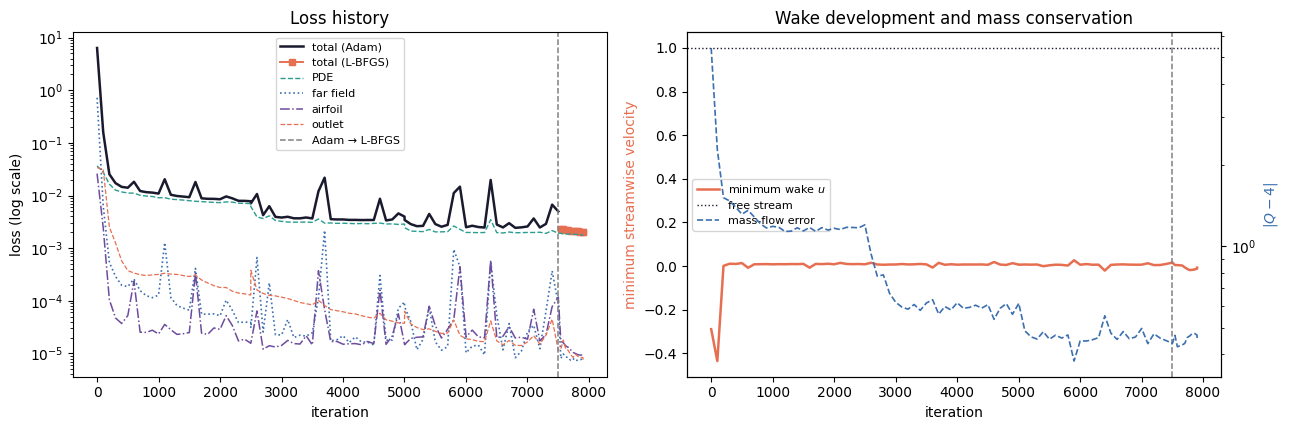

In [11]:
epoch=np.array(history["epoch"])
tot=np.array(history["total"]); pde=np.array(history["pde"])
far=np.array(history["far"]); airfoil=np.array(history["airfoil"]); outlet=np.array(history["outlet"])
wake=np.array(history["wake"]); mass=np.array(history["mass"])
ph=np.array(history["phase"]); am=ph=="Adam"; lm=ph=="LBFGS"
INK="#1A1A2E"; CORAL="#E76F51"; TEAL="#2A9D8F"; PUR="#6D4C9E"; BLUE="#3B6FB0"

fig,ax=plt.subplots(1,2,figsize=(13,4.4))

# loss components
ax[0].semilogy(epoch[am],tot[am],'-',color=INK,lw=1.8,label='total (Adam)')
ax[0].semilogy(epoch[lm],tot[lm],'s-',color=CORAL,ms=4,lw=1.4,label='total (L-BFGS)')
ax[0].semilogy(epoch,pde,'--',color=TEAL,lw=1.0,label='PDE')
ax[0].semilogy(epoch,np.maximum(far,1e-14),':',color=BLUE,lw=1.2,label='far field')
ax[0].semilogy(epoch,np.maximum(airfoil,1e-14),'-.',color=PUR,lw=1.1,label='airfoil')
ax[0].semilogy(epoch,np.maximum(outlet,1e-14),'--',color=CORAL,lw=0.9,label='outlet')
ax[0].axvline(HANDOFF,color='gray',ls='--',lw=1.1,label='Adam → L-BFGS')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss (log scale)')
ax[0].set_title('Loss history'); ax[0].legend(fontsize=8)

# physical indicators
ax2=ax[1]; ax3=ax2.twinx()
ax2.plot(epoch,wake,'-',color=CORAL,lw=1.8,label='minimum wake $u$')
ax2.axhline(1,color=INK,ls=':',lw=1,label='free stream')
ax3.semilogy(epoch,np.maximum(mass,1e-12),'--',color=BLUE,lw=1.2,label='mass-flow error')
ax2.axvline(HANDOFF,color='gray',ls='--',lw=1.1)
ax2.set_xlabel('iteration'); ax2.set_ylabel('minimum streamwise velocity',color=CORAL)
ax3.set_ylabel('$|Q-4|$',color=BLUE); ax2.set_title('Wake development and mass conservation')
h1,l1=ax2.get_legend_handles_labels(); h2,l2=ax3.get_legend_handles_labels()
ax2.legend(h1+h2,l1+l2,fontsize=8,loc='best')
plt.tight_layout(); plt.show()


---

## 12 — Results and validation

We inspect the solution in three levels.

### Level 1 — Flow fields

The velocity and pressure contours should be smooth, the airfoil should have nearly zero velocity, and a symmetric velocity deficit should appear behind the trailing edge.

### Level 2 — Surface aerodynamics

The upper and lower $C_p$ curves should overlap at zero angle of attack. Pressure and viscous stress are then integrated around the closed airfoil contour to estimate $C_D$ and $C_L$.

### Level 3 — Independent checks

Fresh points—not the training points—are used for residual RMS, symmetry, wall slip, outlet pressure, and mass-flow checks. A colorful contour plot alone is not accepted as validation.


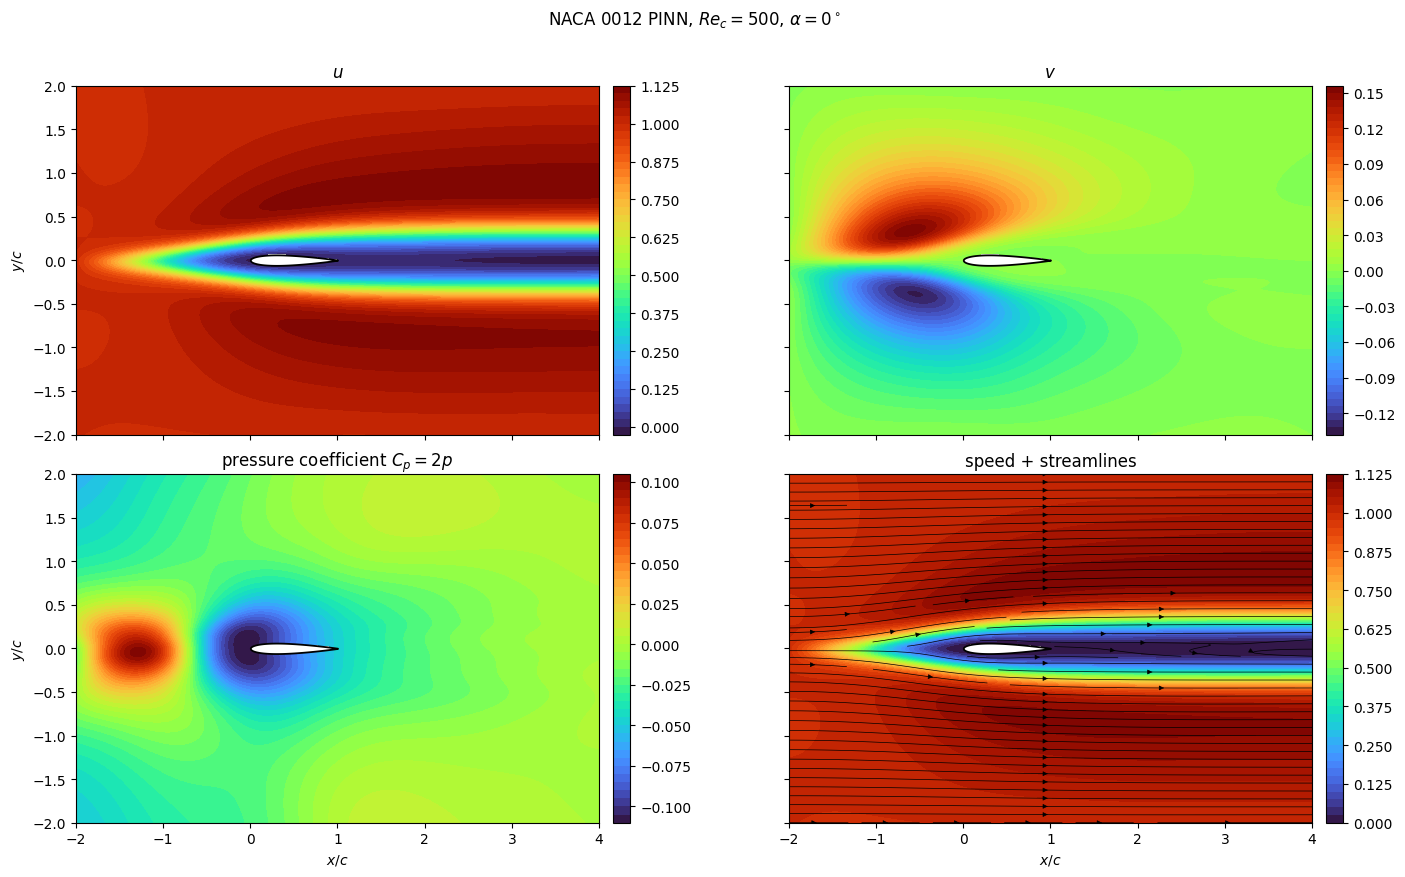

In [12]:
# regular prediction grid
nx,ny=(421,281) if FULL_TRAINING else (181,121)
xg=np.linspace(XMIN,XMAX,nx); yg=np.linspace(YMIN,YMAX,ny)
X,Y=np.meshgrid(xg,yg)
mask=~inside_airfoil_numpy(X,Y)
pts=np.column_stack([X[mask],Y[mask]])

with torch.no_grad():
    pred=model(torch.tensor(pts,dtype=torch.float32,device=device)).cpu().numpy()

U=np.full_like(X,np.nan,dtype=float); V=np.full_like(X,np.nan,dtype=float); P=np.full_like(X,np.nan,dtype=float)
U[mask]=pred[:,0]; V[mask]=pred[:,1]; P[mask]=pred[:,2]
SPEED=np.sqrt(U**2+V**2)

fig,ax=plt.subplots(2,2,figsize=(15,8.6),sharex=True,sharey=True)
fields_plot=[(U,'$u$'),(V,'$v$'),(2*P,'pressure coefficient $C_p=2p$'),(SPEED,'speed + streamlines')]
xpoly=np.linspace(0,1,600); ypoly=naca_thickness_numpy(xpoly)
for a,(F,title) in zip(ax.flat,fields_plot):
    c=a.contourf(X,Y,F,levels=50,cmap='turbo')
    plt.colorbar(c,ax=a,pad=0.02)
    a.fill_between(xpoly,-ypoly,ypoly,color='white',edgecolor='k',lw=1.3,zorder=6)
    a.set_title(title); a.set_aspect('equal'); a.set_xlim(XMIN,XMAX); a.set_ylim(YMIN,YMAX)

# streamlines on the speed panel
ax[1,1].streamplot(xg,yg,np.ma.masked_invalid(U),np.ma.masked_invalid(V),
                   density=1.5,color='k',linewidth=0.5,arrowsize=0.7)
for a in ax[:,0]: a.set_ylabel('$y/c$')
for a in ax[1,:]: a.set_xlabel('$x/c$')
plt.suptitle(f'NACA 0012 PINN, $Re_c={RE_TARGET:g}$, $\\alpha=0^\\circ$',y=1.01)
plt.tight_layout(); plt.show()


independent residual RMS: rx=3.437e-02, ry=1.248e-02, continuity=2.237e-02
far-field RMS errors:     u=1.910e-03, v=2.098e-03
airfoil speed:            RMS=3.091e-03, max=6.757e-03
outlet pressure RMS:      7.546e-04
symmetry RMS:             u=1.797e-02, v=6.909e-03, p=2.424e-03
mass flow at x=-2.0: Q=3.99638  error=-3.62e-03
mass flow at x= 1.5: Q=3.57437  error=-4.26e-01
mass flow at x= 2.5: Q=3.55062  error=-4.49e-01
mass flow at x= 3.5: Q=3.54362  error=-4.56e-01
PINN force coefficients:  C_D=-0.00117, C_L=-0.00007
published C_D band:       [0.1736, 0.1762]
drag benchmark check:     outside band — inspect diagnostics


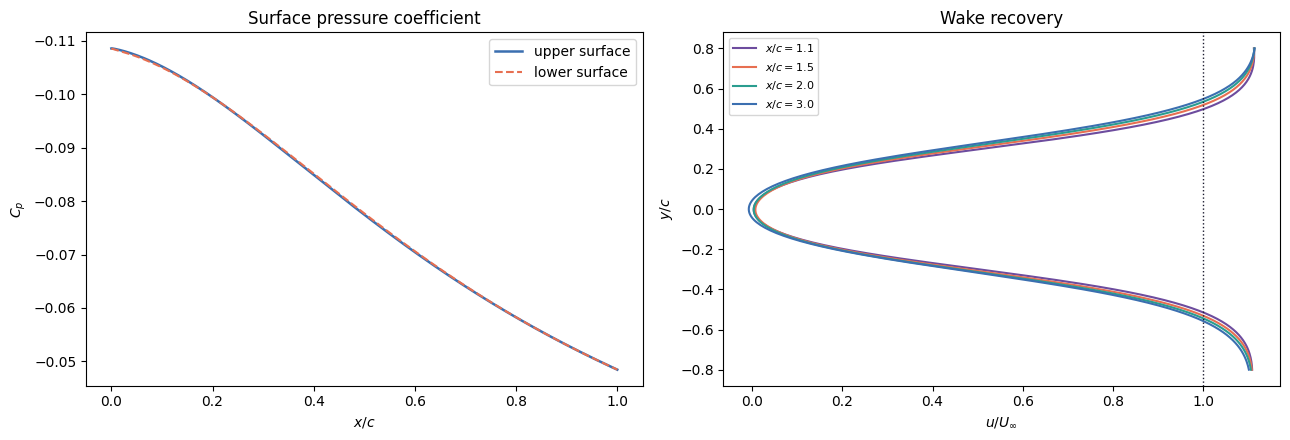

In [13]:
def closed_airfoil_contour(n_surface=401,n_te=25):
    "Counter-clockwise contour: upper TE->LE, lower LE->TE, then trailing edge."
    beta=np.linspace(0,np.pi,n_surface)
    x=0.5*(1-np.cos(beta)); yt=naca_thickness_numpy(x)
    upper=np.column_stack([x[::-1],yt[::-1]])
    lower=np.column_stack([x[1:],-yt[1:]])
    te=np.column_stack([np.ones(n_te),np.linspace(-yt[-1],yt[-1],n_te)])
    q=np.vstack([upper,lower,te[1:-1]])
    return q

def force_coefficients(n_surface=501):
    "Integrate dimensionless pressure and viscous traction around the airfoil."
    q=closed_airfoil_contour(n_surface)
    area=0.5*np.sum(q[:,0]*np.roll(q[:,1],-1)-np.roll(q[:,0],-1)*q[:,1])
    if area<0: q=q[::-1].copy()

    # central-difference tangent, outward normal, and vertex quadrature weights
    dq=np.roll(q,-1,axis=0)-np.roll(q,1,axis=0)
    tangent=dq/(np.linalg.norm(dq,axis=1,keepdims=True)+1e-14)
    normal=np.column_stack([tangent[:,1],-tangent[:,0]])
    ds_prev=np.linalg.norm(q-np.roll(q,1,axis=0),axis=1)
    ds_next=np.linalg.norm(np.roll(q,-1,axis=0)-q,axis=1)
    weights=0.5*(ds_prev+ds_next)

    xy=torch.tensor(q,dtype=torch.float32,device=device,requires_grad=True)
    u,v,p=fields(xy)
    gu=grad(u,xy); gv=grad(v,xy)
    u_x,u_y=gu[:,0:1],gu[:,1:2]
    v_x,v_y=gv[:,0:1],gv[:,1:2]

    nx=torch.tensor(normal[:,0:1],dtype=torch.float32,device=device)
    ny=torch.tensor(normal[:,1:2],dtype=torch.float32,device=device)
    w=torch.tensor(weights[:,None],dtype=torch.float32,device=device)

    sigma_xx=-p+2*u_x/RE_TARGET
    sigma_xy=(u_y+v_x)/RE_TARGET
    sigma_yy=-p+2*v_y/RE_TARGET
    tx=sigma_xx*nx+sigma_xy*ny
    ty=sigma_xy*nx+sigma_yy*ny

    Fx=torch.sum(tx*w).item(); Fy=torch.sum(ty*w).item()
    # coefficient denominator is 0.5*rho*U_inf^2*c; our p scale is rho*U_inf^2
    return 2*Fx,2*Fy

def surface_pressure(n=401):
    beta=torch.linspace(0,math.pi,n,device=device).reshape(-1,1)
    x=0.5*(1-torch.cos(beta)); yt=naca_thickness(x)
    upper=torch.cat([x,yt],dim=1); lower=torch.cat([x,-yt],dim=1)
    with torch.no_grad():
        _,_,pu=fields(upper); _,_,pl=fields(lower)
    return x[:,0].cpu().numpy(),2*pu[:,0].cpu().numpy(),2*pl[:,0].cpu().numpy()

def independent_residual_rms(n=2000):
    xy=sample_interior(n).requires_grad_(True)
    rx,ry,rc=residuals(xy,RE_TARGET)
    return [q.square().mean().sqrt().item() for q in (rx,ry,rc)]

def symmetry_errors(n=800):
    q=sample_box_outside(n,XMIN+0.1,XMAX-0.1,0.03,YMAX-0.1)
    qm=q.clone(); qm[:,1]*=-1
    with torch.no_grad():
        u1,v1,p1=fields(q); u2,v2,p2=fields(qm)
    return (torch.sqrt(((u1-u2)**2).mean()).item(),
            torch.sqrt(((v1+v2)**2).mean()).item(),
            torch.sqrt(((p1-p2)**2).mean()).item())

CD,CL=force_coefficients(601 if FULL_TRAINING else 181)
rx_rms,ry_rms,rc_rms=independent_residual_rms(4000 if FULL_TRAINING else 300)
su,sv,sp=symmetry_errors(1500 if FULL_TRAINING else 200)

with torch.no_grad():
    uf,vf,_=fields(xy_far); ua,va,_=fields(xy_airfoil); _,_,po=fields(xy_out)
    far_u=torch.sqrt(((uf-1)**2).mean()).item(); far_v=torch.sqrt((vf**2).mean()).item()
    wall_rms=torch.sqrt((ua**2+va**2).mean()).item(); wall_max=torch.sqrt(ua**2+va**2).max().item()
    outlet_p=torch.sqrt((po**2).mean()).item()

stations=[XMIN,1.5,2.5,3.5]
flows=[mass_flow(x0) for x0 in stations]
print(f"independent residual RMS: rx={rx_rms:.3e}, ry={ry_rms:.3e}, continuity={rc_rms:.3e}")
print(f"far-field RMS errors:     u={far_u:.3e}, v={far_v:.3e}")
print(f"airfoil speed:            RMS={wall_rms:.3e}, max={wall_max:.3e}")
print(f"outlet pressure RMS:      {outlet_p:.3e}")
print(f"symmetry RMS:             u={su:.3e}, v={sv:.3e}, p={sp:.3e}")
for x0,q in zip(stations,flows): print(f"mass flow at x={x0:4.1f}: Q={q:.5f}  error={q-4:+.2e}")
print(f"PINN force coefficients:  C_D={CD:.5f}, C_L={CL:+.5f}")
print(f"published C_D band:       [{CD_REFERENCE_LOW:.4f}, {CD_REFERENCE_HIGH:.4f}]")
if FULL_TRAINING:
    print("drag benchmark check:     "+("inside published band" if CD_REFERENCE_LOW<=CD<=CD_REFERENCE_HIGH else "outside band — inspect diagnostics"))
else:
    print("CPU mode is a code check; do not judge the benchmark from this short run.")

# surface Cp and wake profiles
xs,cpu,cpl=surface_pressure()
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
ax[0].plot(xs,cpu,color=BLUE,lw=1.8,label='upper surface')
ax[0].plot(xs,cpl,'--',color=CORAL,lw=1.5,label='lower surface')
ax[0].invert_yaxis(); ax[0].set_xlabel('$x/c$'); ax[0].set_ylabel('$C_p$')
ax[0].set_title('Surface pressure coefficient'); ax[0].legend()

for x0,color in zip([1.1,1.5,2.0,3.0],[PUR,CORAL,TEAL,BLUE]):
    y=torch.linspace(-0.8,0.8,241,device=device).reshape(-1,1)
    q=torch.cat([x0*torch.ones_like(y),y],dim=1)
    with torch.no_grad(): u,_,_=fields(q)
    ax[1].plot(u[:,0].cpu(),y[:,0].cpu(),lw=1.5,color=color,label=fr'$x/c={x0}$')
ax[1].axvline(1,color=INK,ls=':',lw=1); ax[1].set_xlabel(r'$u/U_\infty$'); ax[1].set_ylabel('$y/c$')
ax[1].set_title('Wake recovery'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


---

## 13 — Exercises

1. **Point-density study.** Halve and double `N_f` and `N_airfoil`. Compare residual RMS, wall slip, and $C_D$.
2. **Near-airfoil sampling.** Change the fraction assigned to the small box around the airfoil. Which diagnostic responds first?
3. **Domain-size study.** Move the top and bottom boundaries from $\pm2c$ to $\pm3c$, and the outlet from $4c$ to $6c$. Quantify the change in $C_D$.
4. **Trailing-edge convention.** Replace `-0.1015*x**4` with `-0.1036*x**4` to close the trailing edge analytically. Rebuild the mask and compare drag.
5. **Reynolds-number sweep.** Repeat at $Re_c=100,200,500,1000$. Plot $C_D$ against $Re_c$.
6. **Small angle of attack.** Rotate the airfoil by $5^\circ$ while leaving the free stream horizontal. Add $C_L$ as a meaningful validation quantity.
7. **Hard no-slip construction.** Multiply velocity corrections by an approximate distance-to-airfoil function so the wall condition is satisfied exactly.
8. **Published $C_p$ data.** Digitize or import a reference pressure-coefficient curve and calculate an RMS surface error.
9. **Adaptive resampling.** After an initial training stage, add new points where $|r_x|+|r_y|+|r_c|$ is largest.


## 14 — Failure modes to watch for

| Symptom | Cause | Fix |
|---------|-------|-----|
| **Velocity leaks through the airfoil** | no-slip loss is weak or surface points are too sparse | increase `W_AIRFOIL`; increase cosine-spaced boundary points |
| **Leading-edge pressure is noisy** | the leading edge has high curvature and strong gradients | add near-leading-edge interior points; train longer; inspect input scaling |
| **Upper and lower $C_p$ do not overlap** | asymmetric sampling, incomplete convergence, or a coding error in the geometry | check the mask and surface points; inspect symmetry RMS; repeat with a new seed |
| **$C_L$ is not close to zero** | pressure/shear integration is sensitive to small asymmetry | reduce wall slip and PDE residuals before trusting force coefficients |
| **$C_D$ is too small** | wall shear is under-resolved or the flow remains too close to uniform | increase near-wall points and training; inspect the wake deficit |
| **$C_D$ is too large** | outlet or far-field boundaries are too close; surface derivatives are noisy | enlarge the domain; refine the airfoil contour; train L-BFGS longer |
| **Mass flow drifts** | continuity is under-resolved | increase interior points or continuity weighting; inspect independent $r_c$ |
| **L-BFGS stops immediately** | Adam did not provide a useful starting point or loss scales are unbalanced | train Adam longer; examine every component before changing the optimizer |
| **CUDA out-of-memory** | second derivatives retain large graphs | reduce `N_f`; use smaller batches or residual-based resampling |
| **CPU result misses the benchmark** | CPU mode performs only a few iterations | run the full CUDA configuration before interpreting force coefficients |

A force coefficient is a stricter output than a smooth contour plot. Do not tune only to $C_D$ while ignoring residuals and boundary errors.


## 15 — Vocabulary

- **Airfoil** — a streamlined cross-section designed to generate aerodynamic force.
- **Chord ($c$)** — straight-line distance from leading edge to trailing edge.
- **NACA 0012** — symmetric four-digit NACA airfoil with maximum thickness $12\%$ of chord.
- **Leading edge** — rounded front of the airfoil.
- **Trailing edge** — rear junction of the upper and lower surfaces.
- **Angle of attack ($\alpha$)** — angle between the chord line and free-stream velocity.
- **Pressure coefficient ($C_p$)** — $(p-p_\infty)/(\tfrac12\rho U_\infty^2)$; here $C_p=2p$.
- **Drag coefficient ($C_D$)** — streamwise force normalized by $\tfrac12\rho U_\infty^2c$.
- **Lift coefficient ($C_L$)** — cross-stream force normalized by $\tfrac12\rho U_\infty^2c$.
- **Skin friction** — tangential viscous stress acting on the surface.
- **Pressure drag** — drag contribution from the pressure distribution.
- **Wake deficit** — downstream reduction of streamwise velocity relative to the free stream.
- **External flow** — flow around a body rather than through a closed passage.
- **Cosine spacing** — point distribution clustered near both ends of an interval.
- **Traction** — pressure plus viscous stress acting on a surface.
- **Published benchmark** — a reproducible reference case with reported comparison quantities.


## 16 — What You Have Built (and Where the Series Goes)

The notebook preserves the Tutorial 6 workflow while adding the minimum machinery required for a curved aerodynamic body:

| Choice | What it bought |
|--------|---------------|
| chord and free-stream scaling | $Re_c$, $C_p$, $C_D$, and $C_L$ have their standard aerodynamic meanings |
| direct NACA thickness equation | no external geometry file is required |
| rejection sampling | interior physics points never enter the solid airfoil |
| cosine-spaced wall points | better resolution of the leading and trailing edges |
| near-body and wake enrichment | more effort is spent where gradients are strongest |
| direct $(u,v,p)$ network | the implementation stays close to Tutorial 6 |
| Reynolds continuation | the target $Re_c=500$ problem is approached from smoother viscous stages |
| pressure and viscous traction integration | the field solution becomes an engineering force prediction |
| published drag band | validation is tied to reported NACA 0012 results rather than appearance alone |
| independent residual and symmetry checks | a low training loss is not mistaken for a trustworthy solution |

The central engineering lesson is that external-flow PINNs are judged most severely at the wall. A network can produce attractive velocity contours while still having enough slip, pressure error, or derivative noise to corrupt $C_D$.

### Suggested next tutorial

**Tutorial 8 — NACA 0012 at non-zero angle of attack:** rotate the airfoil, predict lift, locate separation, and then extend the formulation to unsteady vortex shedding only after the steady benchmark is under control.

### Final checklist for a credible full run

- [ ] Adam and L-BFGS both reduce the total and component losses
- [ ] independent momentum and continuity RMS values are small
- [ ] airfoil wall speed is small
- [ ] upper/lower fields are symmetric at $\alpha=0^\circ$
- [ ] mass flow remains near $Q=4$
- [ ] $C_L$ is close to zero
- [ ] $C_D$ is reasonably close to the published $0.1736$–$0.1762$ band
- [ ] changing point density or domain size does not move $C_D$ dramatically
